<a href="https://colab.research.google.com/github/shubhamh131/Research-Evidence-Agent/blob/main/bike_rental_analysis_preprocessed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bike Rental Analysis
## Exploratory Data Analysis (EDA) and Data Preprocessing

**Project objective:** Understand the factors associated with hourly bike rental demand and prepare the dataset for the next stage of Machine Learning.

The target variable is **`cnt`**, which represents the total number of bikes rented in an hour. The dataset includes calendar information, weather measurements, and counts of casual and registered users.

This notebook covers data inspection, data-quality checks and exploratory data analysis (sections 1-18), followed by data preprocessing (sections 19-25): missing-value treatment, outlier decisions, validation, feature engineering, encoding, chronological train-test split, scaling and export of model-ready files.

## ***1. IMPORT LIBRARIES***

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Libraries used in the data preprocessing sections
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

## ***2. LOAD DATASET***

The CSV file is loaded into a pandas DataFrame named `df`. A DataFrame stores the records in rows and the variables in columns.

The shape, first few records, and sample rows help confirm that the file loaded and that the column names and values look as expected. This notebook expects `Dataset.csv` to be available in the notebook's working directory.

In [3]:
df = pd.read_csv('/content/Dataset (2) (1) (1).csv')
print('Dataset Loaded Successfully!')

Dataset Loaded Successfully!


In [4]:
df.shape

(17379, 17)

In [5]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1


## ***3. BASIC DATASET INFORMATION***

These checks establish the structure of the dataset before analysis:

- `df.columns` lists the variables available for analysis.
- `df.info()` shows the number of non-null values and the data type of each column.
- `df.describe(include='all')` summarizes numeric and categorical columns.
- `df.sample()` displays selected records so that values can be inspected beyond the first rows.

The dataset is expected to contain 17,379 records and 17 columns. Confirm this using the displayed shape because the actual result depends on the CSV file being loaded.

In [6]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   instant     17379 non-null  int64 
 1   dteday      17379 non-null  object
 2   season      17379 non-null  object
 3   yr          17379 non-null  object
 4   mnth        17379 non-null  object
 5   hr          17379 non-null  int64 
 6   holiday     17379 non-null  object
 7   weekday     17379 non-null  int64 
 8   workingday  17379 non-null  object
 9   weathersit  17379 non-null  object
 10  temp        17379 non-null  object
 11  atemp       17379 non-null  object
 12  hum         17379 non-null  object
 13  windspeed   17379 non-null  object
 14  casual      17379 non-null  object
 15  registered  17379 non-null  object
 16  cnt         17379 non-null  int64 
dtypes: int64(4), object(13)
memory usage: 2.3+ MB


In [8]:
df.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,17379.0,NaN,NaN,NaN,8690.0,5017.0295,1.0,4345.5,8690.0,13034.5,17379.0
dteday,17379,731,31-12-2012,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,17379,5,fall,4496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yr,17379,3,2012,8734,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mnth,17379,13,5,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hr,17379.0,NaN,NaN,NaN,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379,3,No,16878,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekday,17379.0,NaN,NaN,NaN,3.003683,2.005771,0.0,1.0,3.0,5.0,6.0
workingday,17379,3,Working Day,11862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weathersit,17379,5,Clear,11412,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.sample(5, random_state = 42)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
12830,12831,23-06-2012,fall,2012,6,19,No,6,No work,Clear,0.8,0.697,0.27,0.194,185,240,425
8688,8689,02-01-2012,springer,2012,1,20,Yes,1,No work,Clear,0.24,0.2273,0.41,0.2239,5,83,88
7091,7092,28-10-2011,winter,2011,10,2,No,5,Working Day,Clear,0.32,0.303,0.66,0.2836,1,3,4
12230,12231,29-05-2012,summer,2012,5,19,No,2,Working Day,Clear,0.78,0.7121,0.52,0.3582,69,457,526
431,432,20-01-2011,springer,2011,1,0,No,4,Working Day,Clear,0.26,0.2273,0.56,0.3881,5,8,13


## ***4. CHECK MISSING VALUES***

Missing values can affect statistical summaries, charts, and later model training. In this dataset, some missing entries are represented by the text marker `?`, which pandas does not automatically treat as a null value.

The following subsections count these placeholders, convert them to standard missing values, summarize the affected columns, and visualize where missing data occurs.

#### Count '?' placeholders before replacing them

The first check counts literal `?` markers in each column before replacing them. This is necessary because `isnull()` does not identify a question mark as missing data.

In [10]:
question_marks = df.astype('string').eq('?').sum()

print('Question Mark Values:')
print(question_marks[question_marks > 0])

Question Mark Values:
season         6
yr             1
mnth           1
holiday        1
workingday     5
weathersit     4
temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
dtype: Int64


#### Replace '?' with actual missing values

Replacing a standalone `?` (including any surrounding whitespace) with `np.nan` makes the missing entries recognizable to pandas. Once replaced, standard missing-value functions can count and summarize them consistently.

In [11]:
df.replace(r'^\s*\?\s*$', np.nan, regex = True, inplace = True)

#### Missing value summary

The summary reports both the number of missing values and their percentage of all rows for each column. The percentage helps distinguish a small amount of missing data from a column with a larger data-quality problem.

In [12]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

print('Missing Value Summary:\n')
print(missing_summary[missing_summary['Missing Count'] > 0])

Missing Value Summary:

            Missing Count  Missing Percentage
season                  6                0.03
yr                      1                0.01
mnth                    1                0.01
holiday                 1                0.01
workingday              5                0.03
weathersit              4                0.02
temp                   11                0.06
atemp                   6                0.03
hum                     6                0.03
windspeed               5                0.03
casual                  1                0.01
registered              1                0.01


#### Visualize missing values

The bar chart provides a quick visual comparison of missing-value counts by column. If no columns contain missing values, the conditional statement skips the chart because there is nothing to display.

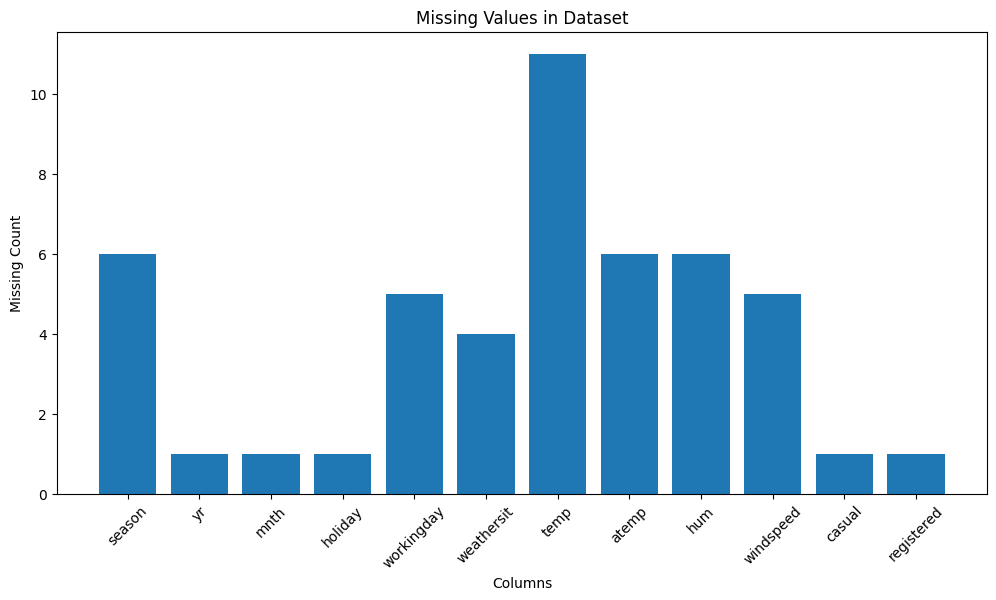

In [13]:
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

if len(missing_data) > 0:
    plt.figure(figsize = (12, 6))
    plt.bar(missing_data.index.astype(str), missing_data.values)
    plt.title('Missing Values in Dataset')
    plt.xlabel('Columns')
    plt.ylabel('Missing Count')
    plt.xticks(rotation = 45)
    plt.show()
else:
    print('No missing values found.')

## ***5. CHECK DUPLICATE RECORDS***

Duplicate rows can unintentionally give repeated observations extra weight in analysis and model training. The code counts exact duplicate rows and removes them if present.

The output shows how many exact duplicate rows were found and reports the dataset shape after duplicate removal.

In [14]:
print('Duplicate Rows:', df.duplicated().sum())

# Remove exact duplicate rows if any exist
df.drop_duplicates(inplace = True)

print('Shape After Duplicate Removal:', df.shape)

Duplicate Rows: 0
Shape After Duplicate Removal: (17379, 17)


## ***6. DATA TYPE CONVERSION***

EDA and preprocessing work more reliably when each variable uses an appropriate data type. Dates should be represented as datetime values, numeric measurements as numbers, and labels as categorical/text values.

The next cells parse `dteday` using the date format present in the CSV and convert the selected numeric columns with `pd.to_numeric`. Invalid values that cannot be converted become missing values and should be reviewed in the subsequent missing-value checks.

#### Convert date into datetime format

The date string in this CSV uses day-month-year order (`DD-MM-YYYY`). Converting it to pandas datetime format enables date validation, chronological sorting, and extraction of calendar features later in the notebook.

In [15]:
df['dteday'] = pd.to_datetime(df['dteday'], format = '%d-%m-%Y', errors = 'coerce')

#### Numerical columns

The selected columns represent numeric values such as hour, temperature, humidity, wind speed, and rental counts. Numeric conversion allows calculations such as averages, ranges, distributions, and correlations to work correctly. Columns that contain unrecognized text will become missing and can then be handled during preprocessing.

In [16]:
numeric_columns = [
    'instant', 'yr', 'mnth', 'hr', 'weekday', 'temp',
    'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'
]

# Convert numerical columns
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors = 'coerce')

# Clean whitespace in categorical columns
categorical_columns = ['season', 'holiday', 'workingday', 'weathersit']

for col in categorical_columns:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].replace("", np.nan)


print('Data Types After Conversion:\n')
print(df.dtypes.to_frame('Data Type'))

print('\nMissing values after conversion:')
display(df.isnull().sum()[df.isnull().sum() > 0])

Data Types After Conversion:

                 Data Type
instant              int64
dteday      datetime64[ns]
season      string[python]
yr                 float64
mnth               float64
hr                   int64
holiday     string[python]
weekday              int64
workingday  string[python]
weathersit  string[python]
temp               float64
atemp              float64
hum                float64
windspeed          float64
casual             float64
registered         float64
cnt                  int64

Missing values after conversion:


,0
season,6
yr,1
mnth,1
holiday,1
workingday,5
weathersit,4
temp,11
atemp,6
hum,6
windspeed,5


## ***7. CORRECT CATEGORY LABELS***

Categorical values should use consistent labels so that a spelling variation does not appear as a separate category in plots or future model features.

The code displays the season labels before correction and replaces `springer` with `spring`. This correction should be made only because the dataset inspection indicates that `springer` is an apparent spelling error; the before-and-after counts let you verify the change.

In [17]:
print('Season values before correction:')
display(df['season'].value_counts(dropna = False))

# Apply only after verifying springer is a spelling error
df['season'] = df['season'].replace({
    'springer': 'spring'
})

print('\nSeason values after correction:')
display(df['season'].value_counts(dropna = False))

Season values before correction:


,count
season,
fall,4496
summer,4409
springer,4236
winter,4232
<NA>,6



Season values after correction:


,count
season,
fall,4496
summer,4409
spring,4236
winter,4232
<NA>,6


## ***8. NUMERICAL FEATURES VISUALIZATION***

Histograms show how values are distributed for `temp`, `atemp`, `hum`, `windspeed`, `casual`, `registered`, and `cnt`. They help identify skewness, concentration of values, spread, and possible unusual observations.

The weather variables are normalized measurements, so their plotted values should not automatically be interpreted as raw degrees Celsius, percent humidity, or wind speed in physical units. `cnt` is the total number of rentals in an hour.

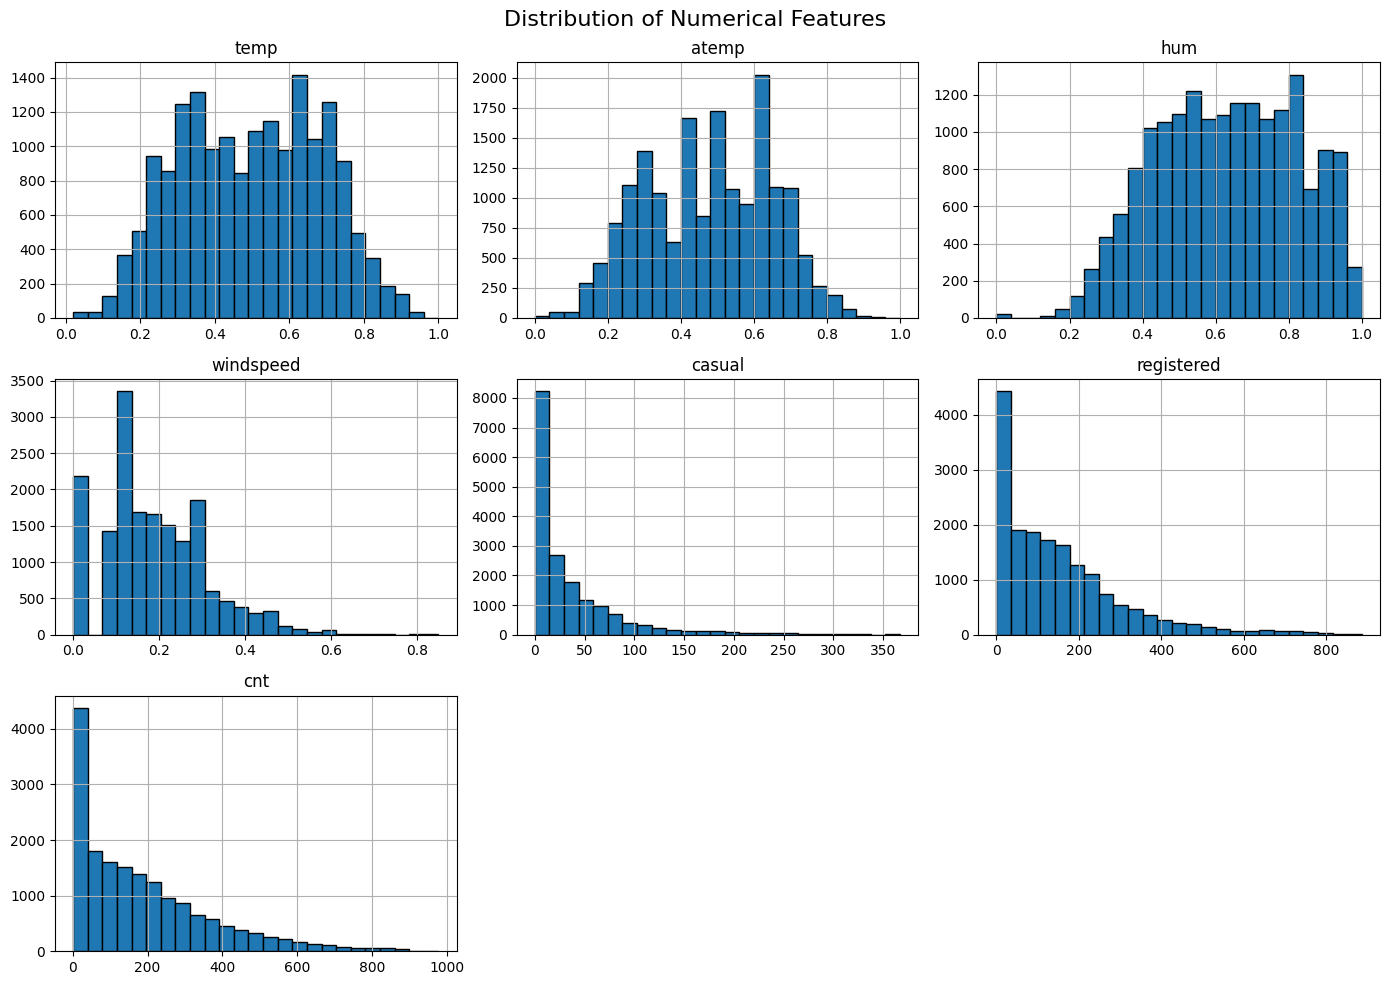

In [18]:
numeric_features = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

df[numeric_features].hist(figsize = (14, 10), bins = 25, edgecolor = 'black')
plt.suptitle('Distribution of Numerical Features', fontsize = 16)
plt.tight_layout()
plt.show()

## ***9. CATEGORICAL FEATURES VISUALIZATION***

Count plots show how frequently each category occurs for season, holiday, working-day status, and weather situation. These plots describe the balance of the observations across categories; they do not by themselves show which category has the highest rental demand.

Rental-demand comparisons by category are examined in later sections.

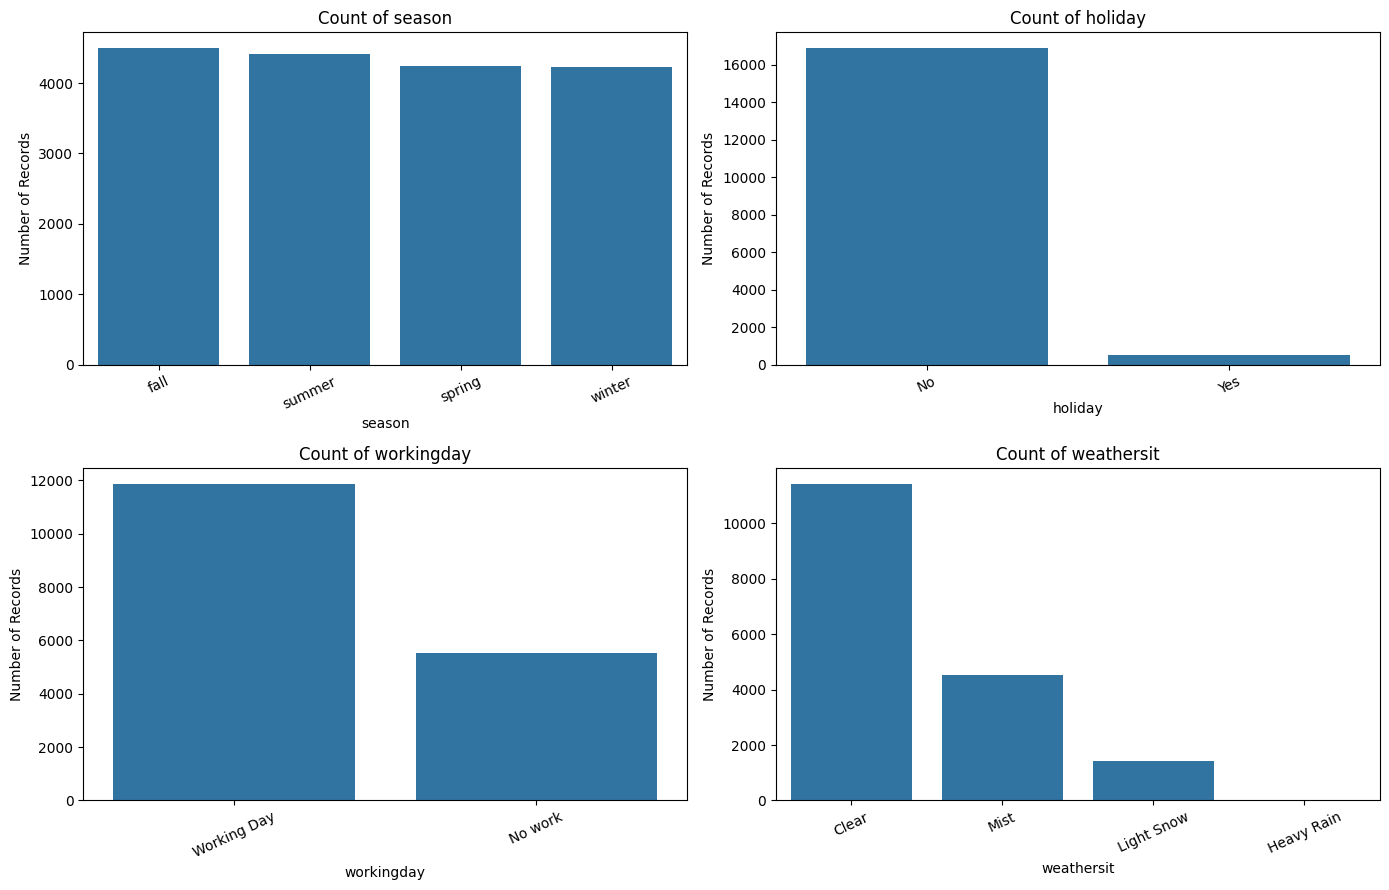

In [19]:
categorical_features = ['season', 'holiday', 'workingday', 'weathersit']

fig, axes = plt.subplots(2, 2, figsize = (14, 9))

for ax, col in zip(axes.flatten(), categorical_features):
    order = df[col].value_counts().index
    sns.countplot(data = df, x = col, order = order, ax = ax)
    ax.set_title(f"Count of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Records')
    ax.tick_params(axis = 'x', rotation = 25)

plt.tight_layout()
plt.show()

## ***10. OUTLIER DETECTION***

Outlier analysis identifies observations that are unusually far from the rest of a variable's distribution. A flagged value is not automatically an error: high bike rental counts can reflect real demand peaks, and weather variables may have naturally uneven distributions.

This section uses boxplots for visual inspection and the interquartile range (IQR) rule to summarize potential outliers. The goal is to investigate unusual values, not to remove them without a reason.

#### Select numerical columns for outlier analysis

The selected columns include normalized weather variables and the casual, registered, and total rental counts. This allows the same outlier-detection approach to be compared across measurements and demand counts.

In [20]:
outlier_columns = [
    'temp', 'atemp', 'hum', 'windspeed',
    'casual', 'registered', 'cnt'
]

print('Columns selected for outlier analysis:')
print(outlier_columns)

Columns selected for outlier analysis:
['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


#### 1. Visualize outliers using boxplots

Boxplots display the median, interquartile range, and points beyond the whiskers. Points outside the whiskers are potential outliers under the plotting convention; they should be interpreted in the context of the feature and the hourly rental setting.

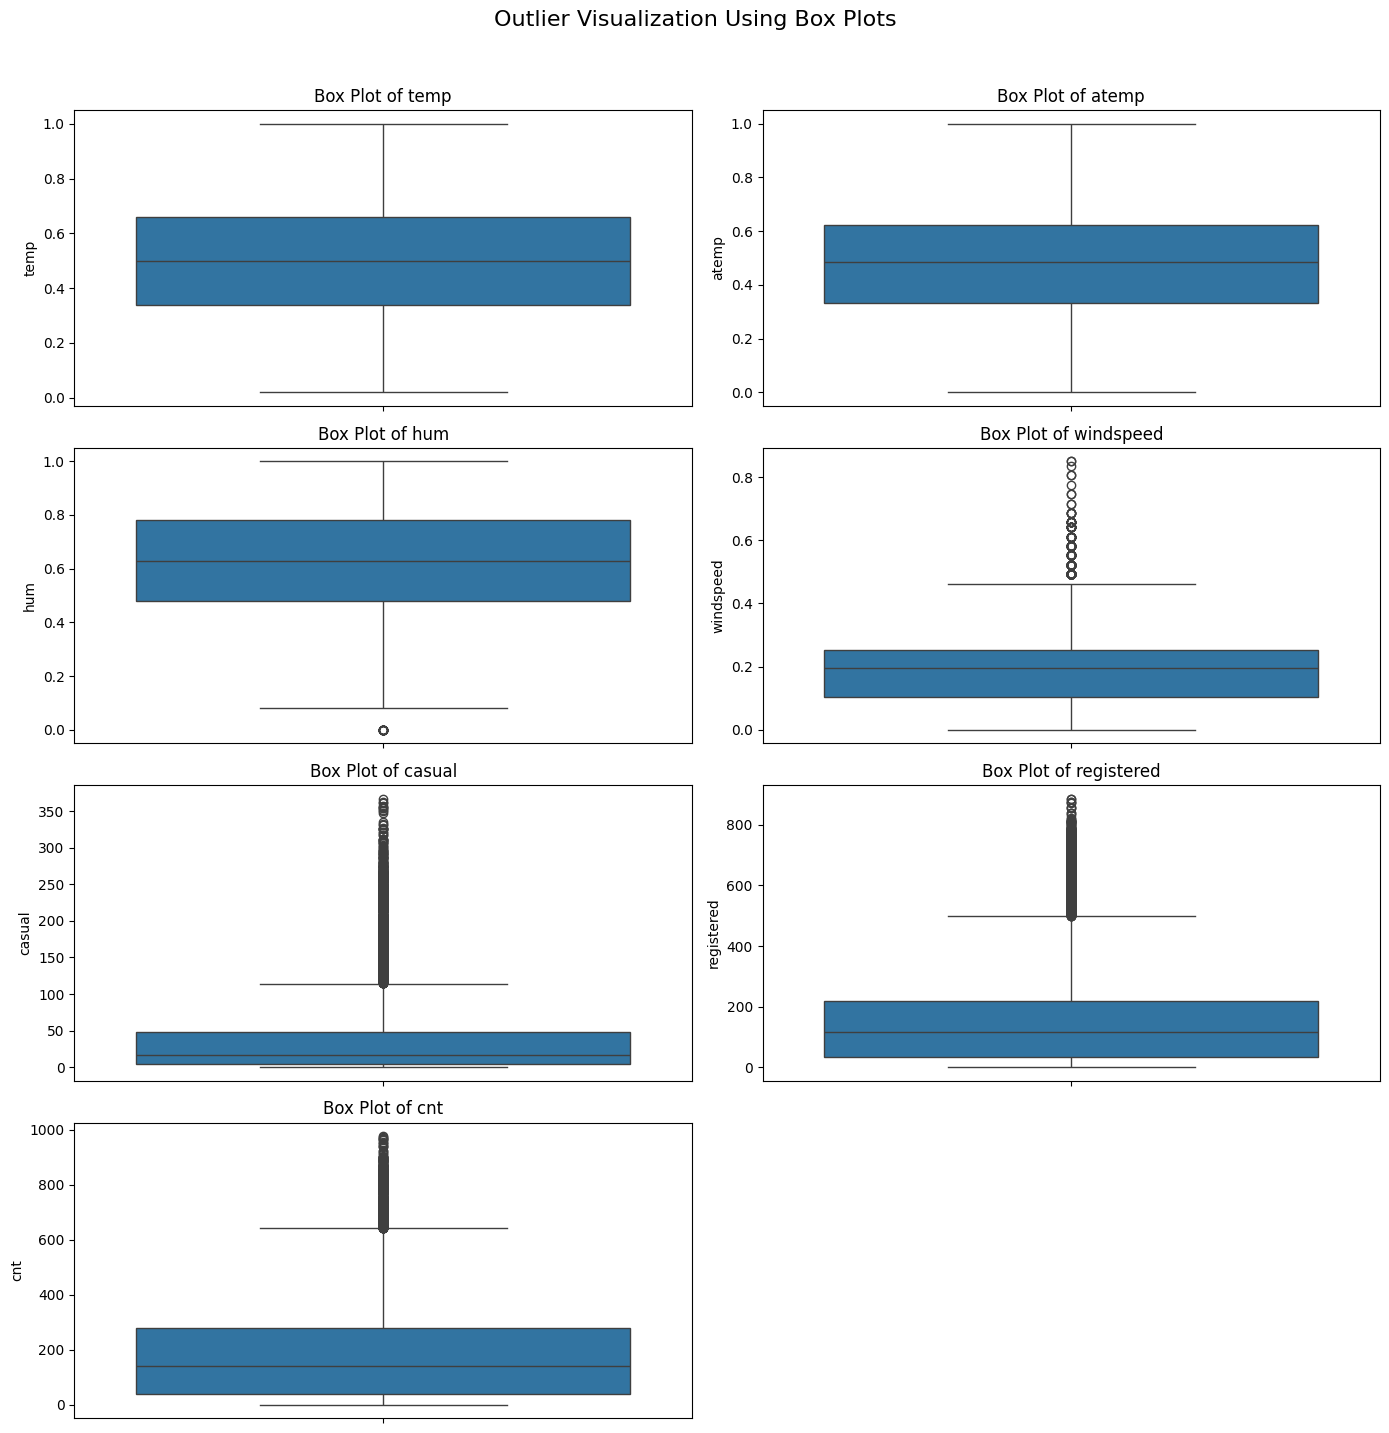

In [21]:
fig, axes = plt.subplots(4, 2, figsize = (14, 14))
axes = axes.flatten()

for ax, col in enumerate(outlier_columns):
    sns.boxplot(y = df[col].dropna(), ax = axes[ax], showfliers = True)
    axes[ax].set_title(f"Box Plot of {col}", fontsize = 12)
    axes[ax].set_xlabel("")
    axes[ax].set_ylabel(col)

# Hide unused subplot
for ax in range(len(outlier_columns), len(axes)):
    axes[ax].set_visible(False)

plt.suptitle('Outlier Visualization Using Box Plots', fontsize = 16, y = 1.02)
plt.tight_layout()
plt.show()

#### 2. Detect outliers using the IQR method

The IQR rule calculates the first quartile (Q1), third quartile (Q3), and interquartile range (`IQR = Q3 - Q1`). Values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` are flagged.

This is a screening rule rather than proof that a record is invalid. In particular, unusually high `cnt` values may be genuine busy hours.

In [22]:
outlier_results = []

for col in outlier_columns:
    values = df[col].dropna()

    if values.empty:
        outlier_results.append({
            'Column': col,
            'Q1': np.nan,
            'Q3': np.nan,
            'IQR': np.nan,
            'Lower Bound': np.nan,
            'Upper Bound': np.nan,
            'Outlier Count': 0,
            'Outlier Percentage': 0.0
        })
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (values < lower_bound) | (values > upper_bound)
    outlier_count = int(outlier_mask.sum())
    outlier_percentage = (outlier_count / len(values)) * 100

    outlier_results.append({
        'Column': col,
        'Q1': round(q1, 3),
        'Q3': round(q3, 3),
        'IQR': round(iqr, 3),
        'Lower Bound': round(lower_bound, 3),
        'Upper Bound': round(upper_bound, 3),
        'Outlier Count': outlier_count,
        'Outlier Percentage': round(outlier_percentage, 2)
    })

print('IQR-based Outlier Detection Completed!')

IQR-based Outlier Detection Completed!


#### 3. Display outlier summary

The summary table lists the IQR bounds, number of flagged records, and percentage flagged for each selected column. Use it alongside the boxplots and domain knowledge to decide whether any observation needs investigation. This notebook does not automatically remove the flagged observations.

In [23]:
outlier_summary = pd.DataFrame(outlier_results)
print('Outlier Detection Summary:\n')
outlier_summary

Outlier Detection Summary:



,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,temp,0.340,0.660,0.320,-0.140,1.140,0,0.00
1,atemp,0.333,0.621,0.288,-0.099,1.053,0,0.00
2,hum,0.480,0.780,0.300,0.030,1.230,22,0.13
3,windspeed,0.104,0.254,0.149,-0.119,0.478,341,1.96
4,casual,4.000,48.000,44.000,-62.000,114.000,1192,6.86
5,registered,34.000,220.000,186.000,-245.000,499.000,680,3.91
6,cnt,40.000,281.000,241.000,-321.500,642.500,505,2.91


## ***11. RENTALS BY SEASON***

This bar chart compares the **average hourly rental count (`cnt`)** across the four season labels. The explicit order makes the seasonal comparison easier to read.

The result can indicate seasonal differences in demand, but it is an average over the observations in each season and does not establish that season alone causes the difference.

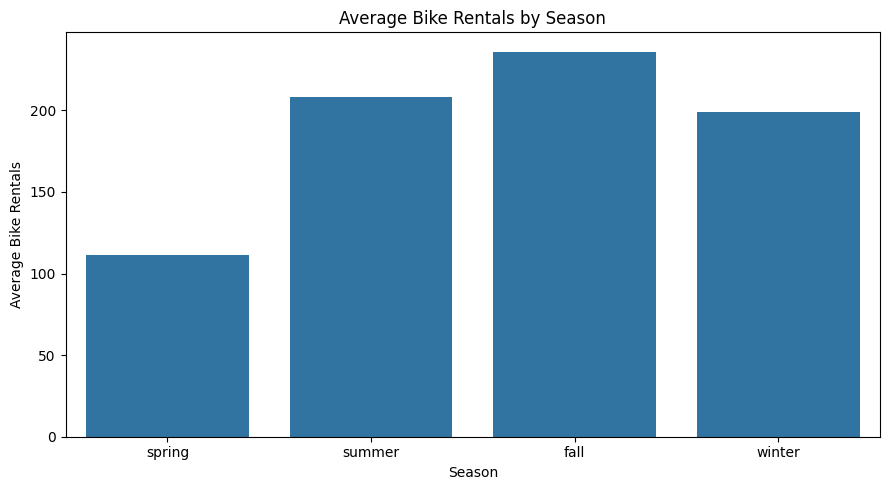

In [24]:
season_order = ['spring', 'summer', 'fall', 'winter']

plt.figure(figsize = (9, 5))

sns.barplot(data = df, x = 'season', y = 'cnt', order = season_order,
            estimator = np.mean, errorbar = None)

plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Bike Rentals')
plt.tight_layout()
plt.show()

## ***12. RENTALS BY WEATHER***

This chart compares average hourly rentals across weather situations. Weather conditions can be associated with changes in demand, so the chart helps explore whether average rental counts differ between the recorded categories.

The interpretation should consider how many observations occur in each weather category, especially if a category is rare.

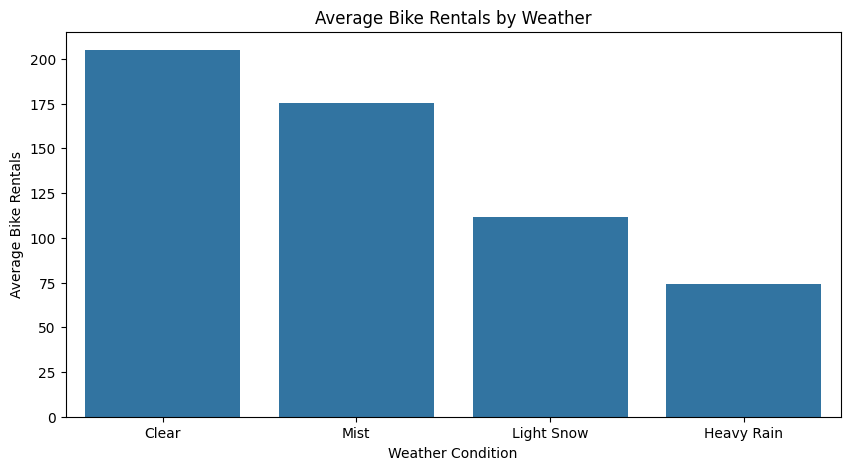

In [25]:
plt.figure(figsize = (10, 5))
sns.barplot(data = df, x = 'weathersit', y = 'cnt', estimator = np.mean, errorbar = None)
plt.title('Average Bike Rentals by Weather')
plt.xlabel('Weather Condition')
plt.ylabel('Average Bike Rentals')
plt.show()

## ***13. RENTALS BY WORKING DAY***

This chart compares average hourly rentals for working and non-working days using the `workingday` category. The comparison helps explore whether typical hourly demand differs depending on the type of day.

The result is descriptive: other variables, including hour, season, and weather, may also contribute to the observed difference.

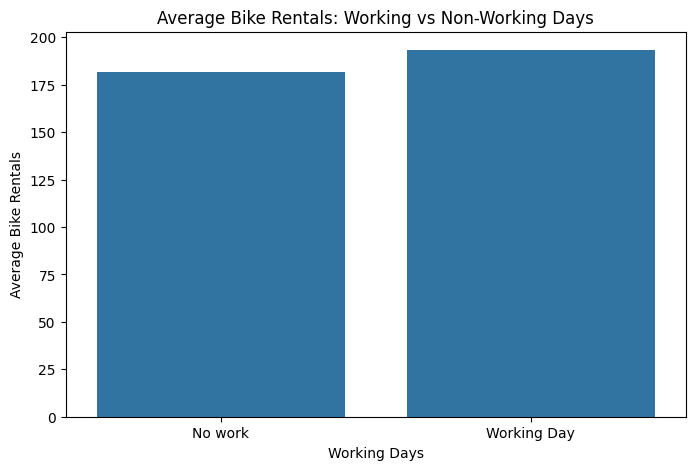

In [26]:
plt.figure(figsize = (8, 5))
sns.barplot(data = df, x = 'workingday', y = 'cnt', estimator = np.mean, errorbar = None)
plt.title('Average Bike Rentals: Working vs Non-Working Days')
plt.xlabel('Working Days')
plt.ylabel('Average Bike Rentals')
plt.show()

## ***14. RENTALS BY HOUR***

The code groups observations by `hr` and calculates the mean `cnt` for each hour from 0 to 23. A line plot makes the daily pattern easier to see and can reveal periods of higher or lower rental demand.

Because this chart averages across all dates, weekday and weekend patterns may be blended together. The next working-day comparison helps separate those patterns.

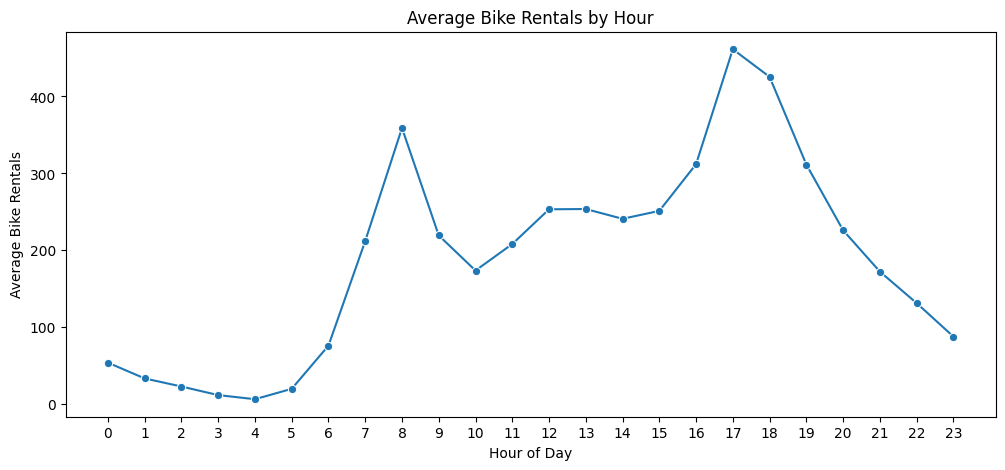

In [27]:
hourly_rentals = df.groupby('hr')['cnt'].mean()

plt.figure(figsize = (12, 5))
sns.lineplot(x = hourly_rentals.index, y = hourly_rentals.values, marker = 'o')
plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(24))
plt.show()

## ***15. RENTALS BY MONTH***

This chart calculates average hourly rentals for each month and reindexes the results to show months 1 through 12 in calendar order. It helps explore recurring within-year variation in bike rental demand.

The plot combines observations from the years present in the dataset, so it does not separately show year-to-year changes.

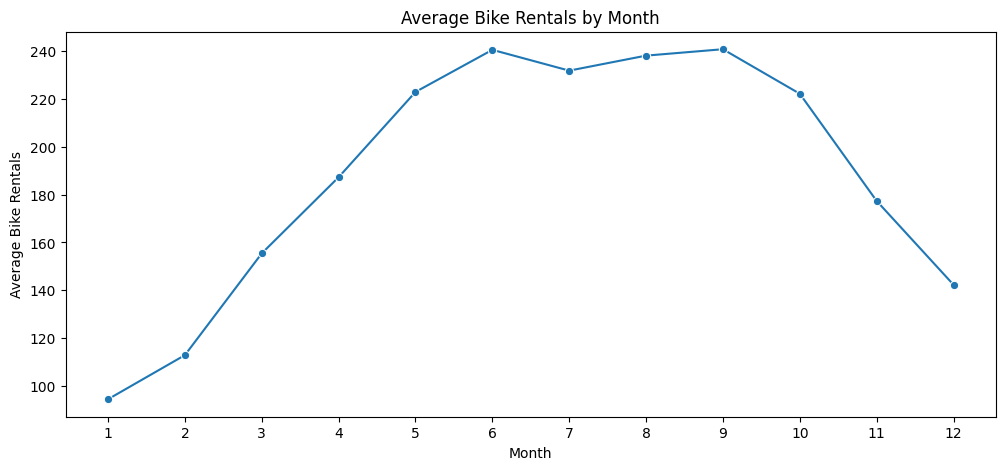

In [28]:
monthly_rentals = df.groupby('mnth')['cnt'].mean().reindex(range(1, 13))

plt.figure(figsize = (12, 5))
sns.lineplot(x = monthly_rentals.index, y = monthly_rentals.values, marker = 'o')
plt.title('Average Bike Rentals by Month')
plt.xlabel('Month')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(1, 13))
plt.show()

## ***16. HOURLY RENTALS - WORKING VS NON-WORKING DAYS***

The line plot groups hourly rental observations by both hour and working-day status. Comparing the two lines helps reveal whether the daily demand profile differs between working and non-working days—for example, whether demand peaks at different times.

These are average values for each hour/category combination, not predictions from a trained model.

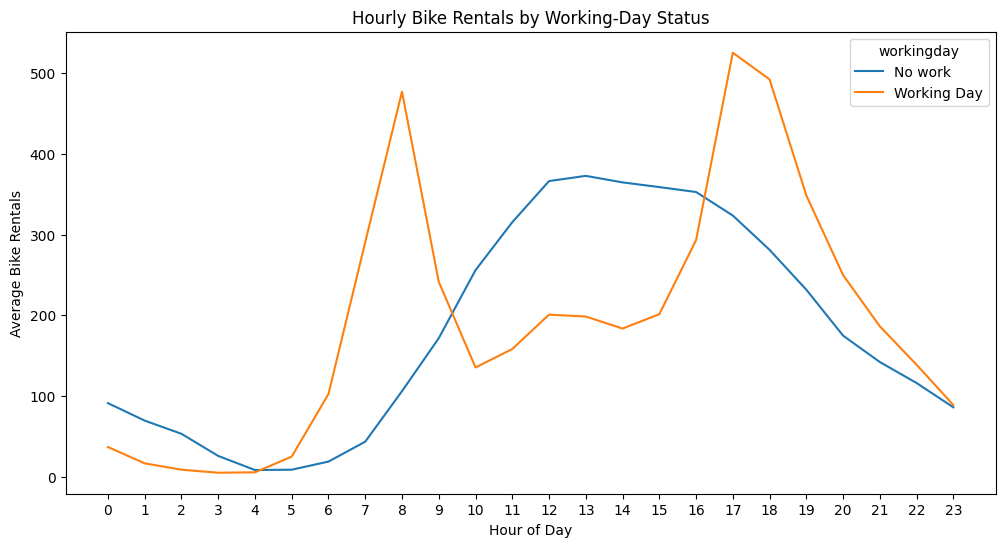

In [29]:
plt.figure(figsize = (12, 6))
sns.lineplot(data = df, x = 'hr', y = 'cnt', hue = 'workingday', estimator = np.mean, errorbar = None)
plt.title('Hourly Bike Rentals by Working-Day Status')
plt.xlabel('Hour of Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(24))
plt.show()

## ***17. TEMPERATURE VS BIKE RENTALS***

The scatter plot displays individual observations with normalized temperature on the x-axis and total hourly rentals (`cnt`) on the y-axis. It helps reveal whether demand tends to rise or fall across the observed temperature range and whether the relationship appears linear or more complex.

Overlapping points are made partially transparent to make dense areas easier to see. Association in this chart does not prove causation.

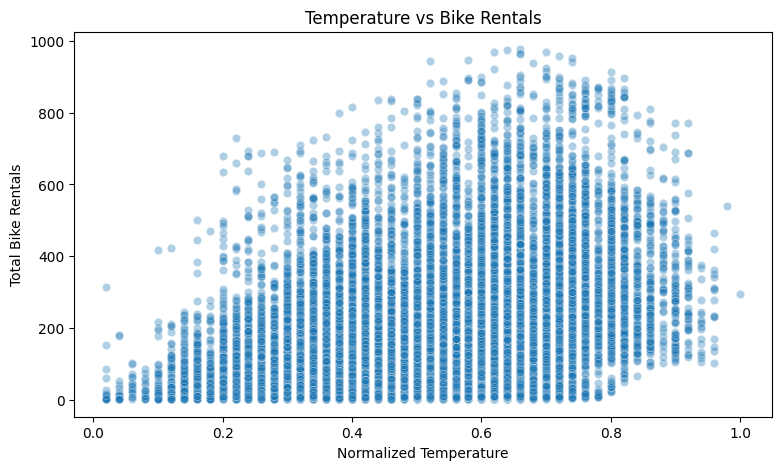

In [30]:
plt.figure(figsize = (9, 5))
sns.scatterplot(data = df, x = 'temp', y = 'cnt', alpha = 0.35)
plt.title('Temperature vs Bike Rentals')
plt.xlabel('Normalized Temperature')
plt.ylabel('Total Bike Rentals')
plt.show()

## ***18. CORRELATION ANALYSIS***

A correlation matrix summarizes the strength and direction of linear relationships between selected numeric variables. Values closer to +1 indicate a stronger positive linear association, values closer to -1 indicate a stronger negative linear association, and values near 0 indicate a weaker linear association.

The heatmap is useful for spotting relationships between weather features and rental counts, as well as possible redundancy between predictors. The `casual` and `registered` columns are included for descriptive analysis because they are components of `cnt`; they must not be used as predictors when building a model to predict `cnt`, since that would cause target leakage.

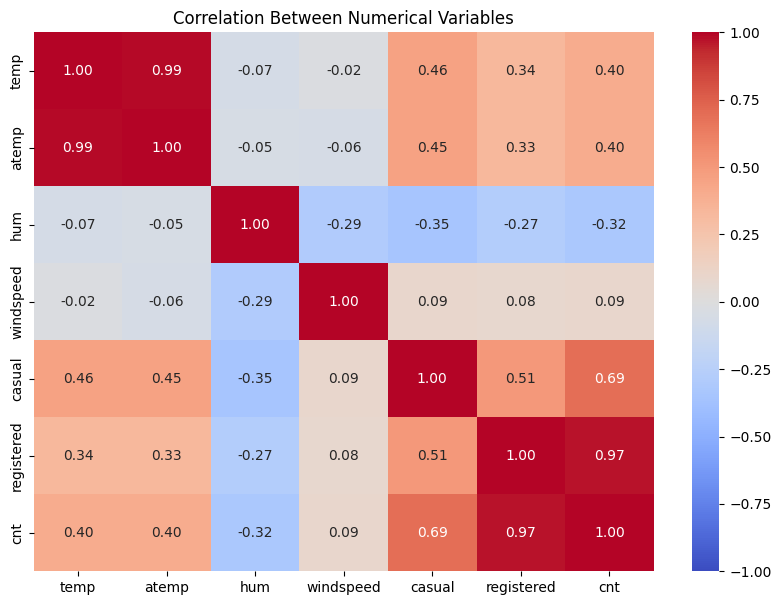

In [31]:
correlation_columns = [
    'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'
]
correlation_matrix = df[correlation_columns].corr(numeric_only = True)

plt.figure(figsize = (10, 7))
sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm', fmt = '.2f', vmin = -1, vmax = 1)
plt.title('Correlation Between Numerical Variables')
plt.show()

In [32]:
print('Correlation with Total Rentals (cnt):')
correlation_matrix['cnt'].drop('cnt').sort_values(ascending = False)

Correlation with Total Rentals (cnt):


,cnt
registered,0.972150
casual,0.694567
temp,0.404557
atemp,0.400912
windspeed,0.093337
hum,-0.322848


## ***19. DATA PREPROCESSING - OVERVIEW***

EDA is finished. Now we turn the raw data into data a model can learn from.

The EDA cells above already did these jobs on `df`: `?` placeholders became real missing values, exact duplicates were checked (none found), data types were converted, and the spelling error `springer` became `spring`. From here on we work on a **copy** called `df_clean`, so the EDA DataFrame stays untouched.

**Problems found in the data and how each one is fixed:**

| Problem | Where | Fix |
|---|---|---|
| 48 missing values in 40 rows (12 columns) | `season`, `yr`, `mnth`, `holiday`, `workingday`, `weathersit`, `temp`, `atemp`, `hum`, `windspeed`, `casual`, `registered` | Column-specific fixes below, no rows deleted |
| Humidity = 0 on one day (22 rows) | `hum` | Treated as a sensor error and re-estimated |
| IQR outliers | `windspeed`, `casual`, `registered`, `cnt` | Checked, then kept (real demand peaks) |
| Text labels | `holiday`, `workingday`, `weathersit`, `season` | Encoded to numbers |
| Time-based patterns hidden in `hr`, `mnth`, `weekday` | calendar columns | Feature engineering |
| `casual` + `registered` = `cnt` | target leakage | Dropped from the model inputs |

Every missing value is filled with the **most reliable source available** for that column, not one blanket median: a date can be rebuilt exactly from `dteday`, a day-level label is the same for all 24 hours of that day, and weather changes smoothly from hour to hour.

### 19.1 Create a working copy and sort by time

**What:** copy `df` into `df_clean`, sort it by date and hour, and build one proper timestamp column `datetime` (date + hour).
**Why:** later steps (filling weather values from neighbouring hours, the train-test split) need the rows in true time order.

The cell also records how many values are missing now, so we can compare at the end. It then picks one real row with the most missing values (`instant = 13`) and follows it through every step.

In [33]:
# Working copy: the EDA DataFrame 'df' stays untouched
df_clean = df.copy()

# Sort in time order and build a full timestamp (date + hour)
df_clean = df_clean.sort_values(['dteday', 'hr']).reset_index(drop = True)
df_clean['datetime'] = df_clean['dteday'] + pd.to_timedelta(df_clean['hr'], unit = 'h')

print('Shape:', df_clean.shape)
print('Duplicate timestamps:', int(df_clean['datetime'].duplicated().sum()))
print('Rows with missing date or target:', int(df_clean[['dteday', 'cnt']].isnull().any(axis = 1).sum()))

missing_before = df_clean.isnull().sum()
print('\nMissing values before preprocessing:')
display(missing_before[missing_before > 0].to_frame('Missing Count'))
print('Total missing cells:', int(missing_before.sum()))
print('Rows with at least one missing value:', int(df_clean.isnull().any(axis = 1).sum()))

# One real row, followed through every step: the row with the most missing values
na_per_row = df_clean.isnull().sum(axis = 1)
example_instant = int(df_clean.loc[na_per_row.idxmax(), 'instant'])
print('\nExample row (instant =', example_instant, ') BEFORE preprocessing:')
display(df_clean[df_clean['instant'] == example_instant].T)

Shape: (17379, 18)
Duplicate timestamps: 0
Rows with missing date or target: 0

Missing values before preprocessing:


,Missing Count
season,6
yr,1
mnth,1
holiday,1
workingday,5
weathersit,4
temp,11
atemp,6
hum,6
windspeed,5


Total missing cells: 48
Rows with at least one missing value: 40

Example row (instant = 13 ) BEFORE preprocessing:


,12
instant,13
dteday,2011-01-01 00:00:00
season,spring
yr,2011.0
mnth,1.0
hr,12
holiday,No
weekday,6
workingday,No work
weathersit,Clear


**Reading the output:** the target `cnt` and the date have no missing values, so no row has to be dropped. The example row is missing `windspeed`, `casual` and `registered`.

### 19.2 Missing `yr` and `mnth` - rebuild from the date

**What:** `yr` and `mnth` are fully determined by `dteday`, so we recalculate them.
**Why this is safe:** the code first checks that every existing `yr` and `mnth` value already agrees with the date. If there are 0 mismatches, the rule is proven on the data and the missing values can be rebuilt with no guessing.

We also check `weekday`. In this dataset `0 = Sunday ... 6 = Saturday` (pandas uses `Monday = 0`, so we shift by one).

In [34]:
# 1) Prove the rule: do existing values already match the date?
yr_mismatch = (df_clean['yr'].notna() & (df_clean['yr'] != df_clean['dteday'].dt.year)).sum()
mnth_mismatch = (df_clean['mnth'].notna() & (df_clean['mnth'] != df_clean['dteday'].dt.month)).sum()
weekday_mismatch = (df_clean['weekday'] != (df_clean['dteday'].dt.dayofweek + 1) % 7).sum()

print('yr mismatches with date    :', int(yr_mismatch))
print('mnth mismatches with date  :', int(mnth_mismatch))
print('weekday mismatches (0=Sun) :', int(weekday_mismatch))

# 2) Rebuild from the date
print('\nMissing before -> yr:', int(df_clean['yr'].isna().sum()), '| mnth:', int(df_clean['mnth'].isna().sum()))
df_clean['yr'] = df_clean['dteday'].dt.year.astype(int)
df_clean['mnth'] = df_clean['dteday'].dt.month.astype(int)
print('Missing after  -> yr:', int(df_clean['yr'].isna().sum()), '| mnth:', int(df_clean['mnth'].isna().sum()))

yr mismatches with date    : 0
mnth mismatches with date  : 0
weekday mismatches (0=Sun) : 0

Missing before -> yr: 1 | mnth: 1
Missing after  -> yr: 0 | mnth: 0


### 19.3 Missing `season`, `holiday`, `workingday` - copy from the same day

**What:** these three columns describe the *day*, not the hour, so all 24 rows of a date must carry the same value. A missing value is filled from another hour of the same date.
**Why this is safe:** the cell first counts dates where the value changes within the day. If that count is 0, the rule is proven.

Afterwards it checks the dataset's own logic: a day is a working day only if it is not Saturday/Sunday and not a holiday.

In [35]:
day_level_cols = ['season', 'holiday', 'workingday']

for col in day_level_cols:
    days_with_conflict = int((df_clean.groupby('dteday')[col].nunique() > 1).sum())
    missing_count = int(df_clean[col].isna().sum())

    # first non-missing value found on the same date
    same_day_value = df_clean.groupby('dteday')[col].transform(
        lambda s: s.dropna().iloc[0] if s.notna().any() else pd.NA
    )
    df_clean[col] = df_clean[col].fillna(same_day_value)

    print(f"{col:11s} | dates where value changes inside a day: {days_with_conflict} | "
          f"missing before: {missing_count} | missing after: {int(df_clean[col].isna().sum())}")

# Logic check: Working Day  <=>  not weekend and not holiday
is_weekend_day = df_clean['weekday'].isin([0, 6])
expected_working = (~is_weekend_day) & (df_clean['holiday'] == 'No')
actual_working = df_clean['workingday'] == 'Working Day'
print('\nRows breaking the workingday rule:', int((expected_working != actual_working).sum()))

season      | dates where value changes inside a day: 0 | missing before: 6 | missing after: 0
holiday     | dates where value changes inside a day: 0 | missing before: 1 | missing after: 0
workingday  | dates where value changes inside a day: 0 | missing before: 5 | missing after: 0

Rows breaking the workingday rule: 0


**A label problem to know about (not an error in our cleaning):** the `season` names in this dataset are shifted compared with the real-world calendar. The next cell prints the date range of each label.

In [36]:
season_rows = []
real_world = {'spring': 'winter', 'summer': 'spring', 'fall': 'summer', 'winter': 'autumn'}
d2011 = df_clean[df_clean['yr'] == 2011]

for label in ['spring', 'summer', 'fall', 'winter']:
    dates = d2011.loc[d2011['season'] == label, 'dteday']
    if label == 'spring':
        # this label wraps around New Year: it starts in December and ends in March
        start = dates[dates.dt.month >= 7].min()
        end = dates[dates.dt.month <= 6].max()
    else:
        start, end = dates.min(), dates.max()
    season_rows.append({'Season label in data': label,
                        'Date range': start.strftime('%d %b') + ' - ' + end.strftime('%d %b'),
                        'Real-world season (northern hemisphere)': real_world[label]})

display(pd.DataFrame(season_rows).set_index('Season label in data'))

,Date range,Real-world season (northern hemisphere)
Season label in data,,
spring,21 Dec - 20 Mar,winter
summer,21 Mar - 20 Jun,spring
fall,21 Jun - 22 Sep,summer
winter,23 Sep - 20 Dec,autumn


**Reading the output:** the label `spring` covers 21 Dec - 20 Mar (real-world winter), `summer` covers 21 Mar - 20 Jun (real-world spring), `fall` covers 21 Jun - 22 Sep (real-world summer), and `winter` covers 23 Sep - 20 Dec (real-world autumn). This is how the dataset was coded. We keep the labels as they are, because the model only needs consistent categories, but **do not describe `spring` as "real spring" in the final report**.

### 19.4 Missing `weathersit` - use the neighbouring hour

**What:** weather type changes slowly, so a missing value is filled with the previous hour's value on the same day (forward fill). If the missing hour is the first of the day, the next hour is used (backward fill).
**Why not the most common value?** "Clear" is the most common weather overall, but the hour before and after the gap tells us what the weather really was.

In [37]:
missing_weather_rows = df_clean[df_clean['weathersit'].isna()][['dteday', 'hr']]
print('Missing weathersit before:', len(missing_weather_rows))

df_clean['weathersit'] = df_clean.groupby('dteday')['weathersit'].transform(lambda s: s.ffill().bfill())

# Safety net: only used if a whole day had no weather value (not expected)
if df_clean['weathersit'].isna().any():
    df_clean['weathersit'] = df_clean['weathersit'].fillna(df_clean['weathersit'].mode()[0])

print('Missing weathersit after :', int(df_clean['weathersit'].isna().sum()))
display(df_clean['weathersit'].value_counts())

Missing weathersit before: 4
Missing weathersit after : 0


,count
weathersit,
Clear,11412
Mist,4544
Light Snow,1420
Heavy Rain,3


### 19.5 Invalid humidity (`hum = 0`)

**What:** humidity of exactly 0 is physically impossible for an outdoor measurement. The next cell checks where the zeros are.

In [38]:
hum_zero = df_clean['hum'] == 0
print('Rows with hum = 0:', int(hum_zero.sum()))
print('Dates affected   :', df_clean.loc[hum_zero, 'dteday'].dt.date.unique())

Rows with hum = 0: 22
Dates affected   : [datetime.date(2011, 3, 10)]


**Reading the output:** all the zeros sit on one single day (10 March 2011). A real weather change does not look like that; it is a sensor failure. We therefore mark these values as missing and re-estimate them together with the other weather gaps in the next step.

### 19.6 Missing `temp`, `atemp`, `hum`, `windspeed` - time interpolation

**What:** temperature, humidity and wind change smoothly through the day. We draw a straight line between the last known hour and the next known hour, using the real timestamp (`method = 'time'`).
**Why not the column median?** The median ignores the time of day. Filling a 3 a.m. gap with the all-day median would be wrong; the neighbouring hours are a much better guess.

The chart afterwards shows the sensor-failure day before and after the fix.

Missing before interpolation:
temp         11
atemp         6
hum          28
windspeed     5

Missing after interpolation:
temp         0
atemp        0
hum          0
windspeed    0


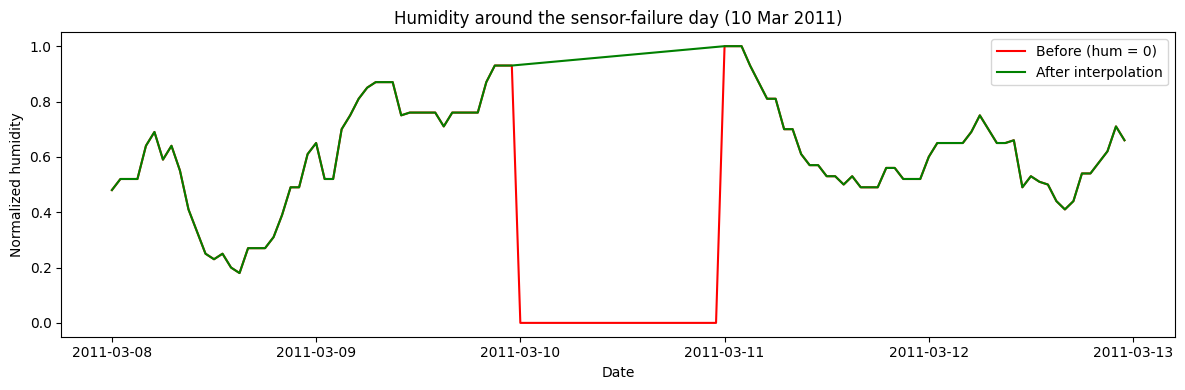

In [39]:
weather_cols = ['temp', 'atemp', 'hum', 'windspeed']
hum_before = df_clean[['datetime', 'hum']].copy()      # saved for the chart

# Humidity = 0 is invalid -> treat as missing
df_clean.loc[df_clean['hum'] == 0, 'hum'] = np.nan

print('Missing before interpolation:')
print(df_clean[weather_cols].isna().sum().to_string())

filled = (
    df_clean.set_index('datetime')[weather_cols]
    .interpolate(method = 'time', limit_direction = 'both')
)
df_clean[weather_cols] = filled.round(4).values

print('\nMissing after interpolation:')
print(df_clean[weather_cols].isna().sum().to_string())

# Chart: the sensor-failure day, before vs after
window = (df_clean['datetime'] >= '2011-03-08') & (df_clean['datetime'] < '2011-03-13')
plt.figure(figsize = (12, 4))
plt.plot(hum_before.loc[window, 'datetime'], hum_before.loc[window, 'hum'], label = 'Before (hum = 0)', color = 'red')
plt.plot(df_clean.loc[window, 'datetime'], df_clean.loc[window, 'hum'], label = 'After interpolation', color = 'green')
plt.title('Humidity around the sensor-failure day (10 Mar 2011)')
plt.xlabel('Date')
plt.ylabel('Normalized humidity')
plt.legend()
plt.tight_layout()
plt.show()

**Reading the chart:** the red line drops to 0 for a whole day. The green line replaces it with a straight line between the last real reading before the failure and the first real reading after it. This is only an estimate (the true humidity during those hours is unknown), but it is far more realistic than 0.

### 19.7 Missing `casual` and `registered` - use the known total

**What:** one row has both values missing but still has `cnt`. Since `casual + registered = cnt` always holds in this data (checked in 19.10), we estimate `casual` from the typical casual share for that hour and day type, and then set `registered = cnt - casual`. If only one of the two is missing, the other is exact: `cnt - known value`.
**Why it matters little for modelling:** both columns are removed from the model inputs later (they add up to the target). We fill them so the cleaned dataset has no gaps.

In [40]:
casual_share = df_clean['casual'] / df_clean['cnt']
typical_share = casual_share.groupby([df_clean['hr'], df_clean['workingday']]).transform('median')

only_reg_missing = df_clean['registered'].isna() & df_clean['casual'].notna()
only_cas_missing = df_clean['casual'].isna() & df_clean['registered'].notna()
both_missing = df_clean['casual'].isna() & df_clean['registered'].isna()

df_clean.loc[only_reg_missing, 'registered'] = df_clean['cnt'] - df_clean['casual']
df_clean.loc[only_cas_missing, 'casual'] = df_clean['cnt'] - df_clean['registered']
df_clean.loc[both_missing, 'casual'] = (df_clean['cnt'] * typical_share).round()
df_clean.loc[both_missing, 'registered'] = df_clean['cnt'] - df_clean['casual']

print('Rows fixed:', int(only_reg_missing.sum() + only_cas_missing.sum() + both_missing.sum()))
print('Missing casual / registered after:', int(df_clean['casual'].isna().sum()), '/', int(df_clean['registered'].isna().sum()))

Rows fixed: 1
Missing casual / registered after: 0 / 0


### 19.8 Missing-value result and the example row after cleaning

The table compares the missing count of every column before and after, and the example row (`instant = 13`) is shown again so you can see exactly what changed.

In [41]:
missing_after = df_clean.isnull().sum()
comparison = pd.DataFrame({'Before': missing_before.drop('datetime', errors = 'ignore'),
                           'After': missing_after.drop('datetime', errors = 'ignore')})
display(comparison[(comparison['Before'] > 0) | (comparison['After'] > 0)])
print('Total missing cells now:', int(missing_after.sum()))

print('\nExample row (instant =', example_instant, ') AFTER preprocessing:')
display(df_clean[df_clean['instant'] == example_instant].T)

,Before,After
season,6,0
yr,1,0
mnth,1,0
holiday,1,0
workingday,5,0
weathersit,4,0
temp,11,0
atemp,6,0
hum,6,0
windspeed,5,0


Total missing cells now: 0

Example row (instant = 13 ) AFTER preprocessing:


,12
instant,13
dteday,2011-01-01 00:00:00
season,spring
yr,2011
mnth,1
hr,12
holiday,No
weekday,6
workingday,No work
weathersit,Clear


**Reading the output:** every column that had gaps now shows 0 missing. In the example row, `windspeed` was filled from the neighbouring hours, `casual` from the typical share for that hour and day type, and `registered` is exactly `cnt - casual`, so the totals still add up.

### 19.9 Outliers - check, then decide

**What:** the EDA flagged IQR outliers in `windspeed`, `casual`, `registered` and `cnt`. Before removing anything, we ask *when* these high values happen. If they happen at rush hours on working days, they are real demand peaks, not errors.

In [42]:
# When do the high total-rental hours (IQR outliers in cnt) happen?
q1, q3 = df_clean['cnt'].quantile([0.25, 0.75])
upper_bound = q3 + 1.5 * (q3 - q1)
cnt_outliers = df_clean[df_clean['cnt'] > upper_bound]

print('cnt upper bound (Q3 + 1.5 x IQR):', round(upper_bound, 1))
print('Outlier rows:', len(cnt_outliers), f'({len(cnt_outliers) / len(df_clean) * 100:.1f}%)')
print('Share of them on working days:', round((cnt_outliers['workingday'] == 'Working Day').mean() * 100, 1), '%')

print('\nHours of the day where these peaks happen:')
display(cnt_outliers['hr'].value_counts().head(6).to_frame('Outlier rows'))

print('Skewness (0 = symmetric, above 1 = strongly right-skewed):')
display(df_clean[['cnt', 'casual', 'registered', 'windspeed']].skew().round(2).to_frame('Skewness'))

# Physical range check for the normalized weather columns
print('Range check (must be within 0 to 1):')
display(df_clean[['temp', 'atemp', 'hum', 'windspeed']].agg(['min', 'max']).T)

# Windspeed zeros
# (checked on the raw data 'df', because interpolation in 19.6 created a few in-between values)
raw_wind = df['windspeed'].dropna()
print('Smallest raw windspeed values:', [float(v) for v in sorted(raw_wind.unique())[:4]])
print('Raw rows with windspeed = 0:', int((raw_wind == 0).sum()), f"({(raw_wind == 0).mean() * 100:.1f}%)")

cnt upper bound (Q3 + 1.5 x IQR): 642.5
Outlier rows: 505 (2.9%)
Share of them on working days: 82.0 %

Hours of the day where these peaks happen:


,Outlier rows
hr,
17,153
18,129
8,127
13,23
12,17
14,15


Skewness (0 = symmetric, above 1 = strongly right-skewed):


,Skewness
cnt,1.28
casual,2.50
registered,1.56
windspeed,0.57


Range check (must be within 0 to 1):


,min,max
temp,0.02,1.0000
atemp,0.00,1.0000
hum,0.08,1.0000
windspeed,0.00,0.8507


Smallest raw windspeed values: [0.0, 0.0896, 0.1045, 0.1343]
Raw rows with windspeed = 0: 2180 (12.5%)


**Decision: no outliers are removed or capped.**

- The `cnt` peaks happen at the hours where demand is genuinely high (see the hour list above). They are exactly the busy hours the business wants to predict. Deleting them would make the model blind to peak demand.
- `windspeed` outliers are valid windy hours; all weather values are inside the 0-1 range.
- `cnt` is right-skewed. Tree models (Decision Tree, Random Forest, Gradient Boosting) are not affected by this. If errors on busy hours stay large in the modelling stage, a `log1p(cnt)` target can be tested there. It is not applied here so that `cnt` stays in real bike counts.

**Windspeed zeros - open question, kept as they are:** about 12.5% of the raw rows have `windspeed = 0`, and the next smallest raw value is 0.0896. Nothing between 0 and 0.0896 exists, which suggests many zeros mean "no reading" rather than "no wind". The data cannot prove it, so we do not change them. Tree models handle this fine; if you use Linear Regression, keep this in mind when interpreting the wind coefficient.

### 19.10 Final validation of the cleaned data

One last set of checks, to prove the cleaned dataset is consistent before we build features on top of it.

In [43]:
checks = {
    'No missing values'                         : int(df_clean.isnull().sum().sum()) == 0,
    'No duplicate rows'                         : int(df_clean.drop(columns = 'datetime').duplicated().sum()) == 0,
    'No duplicate timestamps'                   : int(df_clean['datetime'].duplicated().sum()) == 0,
    'Rows kept (same as raw data)'              : len(df_clean) == len(df),
    'cnt is never negative'                     : bool((df_clean['cnt'] >= 0).all()),
    'casual + registered = cnt'                 : bool((df_clean['casual'] + df_clean['registered'] == df_clean['cnt']).all()),
    'Weather columns inside 0 to 1'             : bool(df_clean[['temp', 'atemp', 'hum', 'windspeed']].apply(lambda s: s.between(0, 1)).all().all()),
    'hum has no zeros left'                     : int((df_clean['hum'] == 0).sum()) == 0,
    'season / holiday / workingday constant per day': bool((df_clean.groupby('dteday')[['season', 'holiday', 'workingday']].nunique() == 1).all().all()),
    'Only 2 years (2011, 2012)'                 : sorted(df_clean['yr'].unique().tolist()) == [2011, 2012],
    'Season labels are exactly 4'               : sorted(df_clean['season'].unique().tolist()) == ['fall', 'spring', 'summer', 'winter'],
}

for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)

print('\nCleaned shape:', df_clean.shape)

PASS - No missing values
PASS - No duplicate rows
PASS - No duplicate timestamps
PASS - Rows kept (same as raw data)
PASS - cnt is never negative
PASS - casual + registered = cnt
PASS - Weather columns inside 0 to 1
PASS - hum has no zeros left
PASS - season / holiday / workingday constant per day
PASS - Only 2 years (2011, 2012)
PASS - Season labels are exactly 4

Cleaned shape: (17379, 18)


## ***20. FEATURE ENGINEERING***

The cleaned data is complete. Now we create a small set of new columns, each one tied to something the EDA showed. Fewer, justified features are better than many weak ones.

| New feature | What it is | EDA evidence |
|---|---|---|
| `is_weekend` | 1 for Saturday/Sunday | Section 13 and 16: weekend demand differs from working days |
| `hr_sin`, `hr_cos` | hour on a 24-hour circle | Section 14: strong daily pattern |
| `mnth_sin`, `mnth_cos` | month on a 12-month circle | Section 15: yearly pattern |
| `weekday_sin`, `weekday_cos` | weekday on a 7-day circle | Weekly cycle |
| `time_period` | Night / Morning / Afternoon / Evening / Late Night | Section 14: daily pattern in broad blocks |
| `is_rush_hour` | 1 for hours 7-9 and 16-19 | Section 14: peaks at 8 and 17-18 |
| `rush_hour_workingday` | rush hour x working day | Section 16: the commute peak exists only on working days |
| `temp_squared`, `temp_hum_interaction` | non-linear weather terms | Section 17: temperature effect is not a straight line |

#### 20.1 Weekend flag, cyclical encoding, time-of-day

**Why sine/cosine for time?** Hour 23 and hour 0 are only one hour apart, but as plain numbers they are 23 apart. Putting the hour on a circle with `sin` and `cos` makes the model see 23 and 0 as neighbours. The same idea applies to month and weekday.

The cell prints one real example: hours 22, 23, 0 and 1.

In [44]:
# Weekend flag (dataset convention: 0 = Sunday, 6 = Saturday)
df_clean['is_weekend'] = df_clean['weekday'].isin([0, 6]).astype(int)

# Cyclical encoding of hour, month and weekday
df_clean['hr_sin'] = np.sin(2 * np.pi * df_clean['hr'] / 24)
df_clean['hr_cos'] = np.cos(2 * np.pi * df_clean['hr'] / 24)

df_clean['mnth_sin'] = np.sin(2 * np.pi * (df_clean['mnth'] - 1) / 12)
df_clean['mnth_cos'] = np.cos(2 * np.pi * (df_clean['mnth'] - 1) / 12)

df_clean['weekday_sin'] = np.sin(2 * np.pi * df_clean['weekday'] / 7)
df_clean['weekday_cos'] = np.cos(2 * np.pi * df_clean['weekday'] / 7)

# One real example: hours 22, 23, 0, 1
example_hours = (
    df_clean.loc[df_clean['hr'].isin([22, 23, 0, 1]), ['hr', 'hr_sin', 'hr_cos']]
    .drop_duplicates('hr')
    .sort_values('hr')
    .round(3)
)
display(example_hours)

,hr,hr_sin,hr_cos
0,0,0.000,1.000
1,1,0.259,0.966
22,22,-0.500,0.866
23,23,-0.259,0.966


**Reading the output:** hour 23 has `(sin, cos) = (-0.259, 0.966)` and hour 0 has `(0, 1)`. These two points are close to each other on the circle, which is the real situation, so the model now treats midnight as a continuation of the evening.

#### 20.2 Time-of-day blocks and rush hour

`time_period` groups the 24 hours into five blocks. `is_rush_hour` marks the commute hours (7-9 and 16-19) that the EDA hourly chart showed as the peaks. `rush_hour_workingday` is 1 only when it is a rush hour **and** a working day.

The table below checks the idea on real numbers: average rentals per hour, split by working day and rush hour.

In [45]:
df_clean['time_period'] = pd.cut(
    df_clean['hr'],
    bins = [-1, 5, 10, 15, 19, 23],
    labels = ['Night', 'Morning', 'Afternoon', 'Evening', 'Late Night']
).astype(str)

df_clean['is_rush_hour'] = df_clean['hr'].isin([7, 8, 9, 16, 17, 18, 19]).astype(int)

working_flag = (df_clean['workingday'] == 'Working Day').astype(int)
df_clean['rush_hour_workingday'] = df_clean['is_rush_hour'] * working_flag

# Evidence: average rentals per hour
evidence = df_clean.groupby(['workingday', 'is_rush_hour'])['cnt'].mean().round(1).unstack()
evidence.columns = ['Not rush hour', 'Rush hour']
display(evidence)

,Not rush hour,Rush hour
workingday,,
No work,167.2,215.6
Working Day,115.1,381.3


**Reading the output:** on working days, rush hours average about 381 rentals against about 115 at other hours (more than 3x). On non-working days the gap is small (about 216 vs 167). So rush hour only matters strongly on working days, and that is why the interaction column `rush_hour_workingday` exists.

#### 20.3 Weather features

`temp_squared` lets a model capture that rentals do not rise in a straight line with temperature. `temp_hum_interaction` captures that hot and humid weather feels different from hot and dry. Tree models can find these patterns on their own; the columns mainly help Linear Regression.

In [46]:
df_clean['temp_squared'] = df_clean['temp'] ** 2
df_clean['temp_hum_interaction'] = df_clean['temp'] * df_clean['hum']

new_features = [
    'is_weekend', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos',
    'time_period', 'is_rush_hour', 'rush_hour_workingday', 'temp_squared', 'temp_hum_interaction'
]
print('New features created:', len(new_features))
print('Missing values in new features:', int(df_clean[new_features].isnull().sum().sum()))
display(df_clean[new_features].head())

New features created: 12
Missing values in new features: 0


,is_weekend,hr_sin,hr_cos,mnth_sin,mnth_cos,weekday_sin,weekday_cos,time_period,is_rush_hour,rush_hour_workingday,temp_squared,temp_hum_interaction
0,1,0.000000,1.000000,0.0,1.0,-0.781831,0.62349,Night,0,0,0.0576,0.1944
1,1,0.258819,0.965926,0.0,1.0,-0.781831,0.62349,Night,0,0,0.0484,0.1760
2,1,0.500000,0.866025,0.0,1.0,-0.781831,0.62349,Night,0,0,0.0484,0.1705
3,1,0.707107,0.707107,0.0,1.0,-0.781831,0.62349,Night,0,0,0.0576,0.1800
4,1,0.866025,0.500000,0.0,1.0,-0.781831,0.62349,Night,0,0,0.0576,0.1800


## ***21. ENCODING CATEGORICAL VARIABLES***

Models need numbers, not words. Each text column gets the encoding that fits its meaning:

| Column | Values | Encoding | Reason |
|---|---|---|---|
| `holiday` | No / Yes | 0 / 1 | Two values only |
| `workingday` | No work / Working Day | 0 / 1 | Two values only |
| `yr` | 2011 / 2012 | 0 / 1 | Two values only (dataset convention) |
| `weathersit` | Clear, Mist, Light Snow, Heavy Rain | 1, 2, 3, 4 | Has a natural order (worse weather = higher number). One-hot would also create a `Heavy Rain` column with only 3 rows |
| `season` | spring, summer, fall, winter | One-hot | No order between seasons |
| `time_period` | 5 blocks | One-hot | No order |

For one-hot columns, one category is dropped (`drop_first = True`): `fall` for season and `Afternoon` for time period. Its value is already implied when all the others are 0, and keeping it would make Linear Regression's columns perfectly dependent on each other.

`df_clean` keeps readable labels; the encoded copy is `df_encoded`.

In [47]:
df_encoded = df_clean.copy()

# Binary columns
df_encoded['holiday'] = (df_encoded['holiday'] == 'Yes').astype(int)
df_encoded['workingday'] = (df_encoded['workingday'] == 'Working Day').astype(int)
df_encoded['yr'] = (df_encoded['yr'] - 2011).astype(int)

# Ordered column: weather severity
weather_order = {'Clear': 1, 'Mist': 2, 'Light Snow': 3, 'Heavy Rain': 4}
unmapped = ~df_encoded['weathersit'].isin(weather_order.keys())
print('Weather labels not in the mapping:', int(unmapped.sum()))
df_encoded['weathersit'] = df_encoded['weathersit'].map(weather_order).astype(int)

# Unordered columns: one-hot
df_encoded = pd.get_dummies(df_encoded, columns = ['season', 'time_period'], drop_first = True, dtype = int)
df_encoded.columns = df_encoded.columns.str.replace(' ', '_')

print('Shape after encoding:', df_encoded.shape)
print('One-hot columns created:', [c for c in df_encoded.columns if c.startswith(('season_', 'time_period_'))])

Weather labels not in the mapping: 0
Shape after encoding: (17379, 35)
One-hot columns created: ['season_spring', 'season_summer', 'season_winter', 'time_period_Evening', 'time_period_Late_Night', 'time_period_Morning', 'time_period_Night']


## ***22. CHOOSING THE MODEL INPUTS***

Not every column should go into the model.

| Column(s) dropped | Reason |
|---|---|
| `cnt` | It is the target `y` |
| `casual`, `registered` | They add up to `cnt`. Using them would hand the model the answer (**target leakage**) |
| `instant` | Just a row number |
| `dteday`, `datetime` | The useful parts (year, hour, weekday, month) are already extracted |
| `atemp` | Almost a copy of `temp` (correlation printed below), so it adds no new information |
| `mnth`, `weekday` | Replaced by their sine/cosine versions |

`hr` is kept as a plain number next to `hr_sin`/`hr_cos`, because it is the strongest pattern in the EDA and tree models split on it directly.

In [48]:
print('Correlation temp vs atemp:', round(df_clean[['temp', 'atemp']].corr().iloc[0, 1], 3))

drop_columns = ['cnt', 'casual', 'registered', 'instant', 'dteday', 'datetime', 'atemp', 'mnth', 'weekday']

X = df_encoded.drop(columns = drop_columns)
y = df_encoded['cnt']

print('\nX shape:', X.shape)
print('y shape:', y.shape)
print('\nModel input columns (' + str(X.shape[1]) + '):')
print(X.columns.tolist())

Correlation temp vs atemp: 0.988

X shape: (17379, 26)
y shape: (17379,)

Model input columns (26):
['yr', 'hr', 'holiday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'is_weekend', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos', 'is_rush_hour', 'rush_hour_workingday', 'temp_squared', 'temp_hum_interaction', 'season_spring', 'season_summer', 'season_winter', 'time_period_Evening', 'time_period_Late_Night', 'time_period_Morning', 'time_period_Night']


## ***23. TRAIN-TEST SPLIT (CHRONOLOGICAL)***

**What:** the first 80% of the timeline is training data; the last 20% is test data. No shuffling.
**Why:** this is time-series data and the business wants to predict **future** demand. A random split would let the model train on hours that sit between test hours, which makes scores look better than they will be in real use.

The split comes **before** scaling, so the test data cannot influence anything the scaler learns.

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, shuffle = False)





train_dates = df_clean.loc[X_train.index, 'dteday']
test_dates = df_clean.loc[X_test.index, 'dteday']

print('Training rows:', X_train.shape[0], '| from', train_dates.min().date(), 'to', train_dates.max().date())
print('Testing rows :', X_test.shape[0], '| from', test_dates.min().date(), 'to', test_dates.max().date())

print('\nAverage rentals per hour: train =', round(y_train.mean(), 1), '| test =', round(y_test.mean(), 1))
print('Months present in test data:', sorted(df_clean.loc[X_test.index, 'mnth'].unique().tolist()))

Training rows: 13903 | from 2011-01-01 to 2012-08-07
Testing rows : 3476 | from 2012-08-07 to 2012-12-31

Average rentals per hour: train = 174.6 | test = 248.8
Months present in test data: [8, 9, 10, 11, 12]


**Important for later:** the test set is the last months of 2012 only (August to December), and its average rentals per hour are clearly higher than the training average (see the output above), because the service was busier in 2012. Test scores will describe how well the model predicts *that* period. Every test row is from 2012 (`yr = 1`), and the `season_spring` column is almost never 1 in the test data. This is realistic for forecasting, but remember it when you compare the test score with the cross-validation score.

## ***24. SCALING***

**What:** `StandardScaler` rewrites a column so that its training mean is 0 and its spread is 1.
**Why:** Linear Regression and distance-based methods are sensitive to column size (`hr` goes 0-23, `temp` only 0-1). Tree models do not care, so scaling never hurts them.

**Rules we follow:**
- Only continuous columns are scaled. Binary, one-hot and sine/cosine columns are left alone.
- The scaler learns its mean and spread from **training data only** (`fit`), then applies them to the test data (`transform`). Otherwise test information leaks into training.
- The target `cnt` is not scaled; it stays in real bike counts.

In [50]:
scale_columns = ['hr', 'temp', 'hum', 'windspeed', 'temp_squared', 'temp_hum_interaction', 'weathersit']

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_columns] = scaler.fit_transform(X_train[scale_columns])   # learn from train only
X_test_scaled[scale_columns] = scaler.transform(X_test[scale_columns])         # apply to test

# One real example: the first test row, before and after scaling
example = pd.DataFrame({
    'Original value': X_test.iloc[0][scale_columns],
    'Scaled value': X_test_scaled.iloc[0][scale_columns],
    'Train mean used': scaler.mean_,
    'Train std used': scaler.scale_,
}).round(3)
display(example)

print('Train means after scaling (should be ~0):')
print(X_train_scaled[scale_columns].mean().round(3).to_string())
print('\nTrain std after scaling (should be ~1):')
print(X_train_scaled[scale_columns].std(ddof = 0).round(3).to_string())

,Original value,Scaled value,Train mean used,Train std used
hr,12.000,0.066,11.547,6.912
temp,0.800,1.522,0.499,0.198
hum,0.550,-0.378,0.625,0.197
windspeed,0.134,-0.486,0.194,0.123
temp_squared,0.640,1.757,0.288,0.200
temp_hum_interaction,0.440,0.890,0.309,0.147
weathersit,2.000,0.900,1.420,0.644


Train means after scaling (should be ~0):
hr                     -0.0
temp                   -0.0
hum                    -0.0
windspeed               0.0
temp_squared           -0.0
temp_hum_interaction   -0.0
weathersit              0.0

Train std after scaling (should be ~1):
hr                      1.0
temp                    1.0
hum                     1.0
windspeed               1.0
temp_squared            1.0
temp_hum_interaction    1.0
weathersit              1.0


**Reading the output:** for the first test row, `Scaled = (Original - Train mean) / Train std`. Train means are 0 and train spreads are 1 by design. Test columns will not be exactly 0 and 1, which is normal: they come from a different period and must not be re-fitted.

## ***25. FINAL CHECKS AND EXPORT***

Last checks before the data goes to the modelling stage, then the files are saved:

- `bike_rental_cleaned.csv` - cleaned data with readable labels plus the engineered features (for reporting and dashboards)
- `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv` - model-ready (encoded + scaled)
- `preprocessing_artifacts.joblib` - the fitted scaler and column lists. The **deployment** stage needs this to apply the same preprocessing to new data.

In [51]:
# Final checks on the model-ready data
print('Same columns in train and test :', X_train_scaled.columns.tolist() == X_test_scaled.columns.tolist())
print('Missing in X_train / X_test    :', int(X_train_scaled.isnull().sum().sum()), '/', int(X_test_scaled.isnull().sum().sum()))
print('Missing in y_train / y_test    :', int(y_train.isnull().sum()), '/', int(y_test.isnull().sum()))
print('Non-numeric columns in X       :', X_train_scaled.select_dtypes(exclude = np.number).columns.tolist())
print('Leakage columns present in X   :', [c for c in ['cnt', 'casual', 'registered'] if c in X_train_scaled.columns])
print('Train / test rows              :', X_train_scaled.shape[0], '/', X_test_scaled.shape[0])
print('Number of model input columns  :', X_train_scaled.shape[1])

# Export
df_clean.to_csv('bike_rental_cleaned.csv', index = False)

X_train_scaled.to_csv('X_train.csv', index = False)
X_test_scaled.to_csv('X_test.csv', index = False)
y_train.to_csv('y_train.csv', index = False)
y_test.to_csv('y_test.csv', index = False)

joblib.dump(
    {
        'scaler': scaler,
        'scale_columns': scale_columns,
        'feature_columns': X_train_scaled.columns.tolist(),
        'weather_order': weather_order,
    },
    'preprocessing_artifacts.joblib'
)

print('\nFiles saved: bike_rental_cleaned.csv, X_train.csv, X_test.csv, y_train.csv, y_test.csv, preprocessing_artifacts.joblib')

Same columns in train and test : True
Missing in X_train / X_test    : 0 / 0
Missing in y_train / y_test    : 0 / 0
Non-numeric columns in X       : []
Leakage columns present in X   : []
Train / test rows              : 13903 / 3476
Number of model input columns  : 26

Files saved: bike_rental_cleaned.csv, X_train.csv, X_test.csv, y_train.csv, y_test.csv, preprocessing_artifacts.joblib


### Data preprocessing summary

| Step | What was done | Result |
|---|---|---|
| 19.1 | Copy of EDA data, sorted by time, `datetime` column added | Rows in true time order |
| 19.2 | `yr`, `mnth` rebuilt from `dteday` (rule proven first) | 0 missing |
| 19.3 | `season`, `holiday`, `workingday` filled from the same day | 0 missing |
| 19.4 | `weathersit` filled from the neighbouring hour | 0 missing |
| 19.5-19.6 | Invalid `hum = 0` day fixed; weather numbers filled by time interpolation | 0 missing |
| 19.7 | `casual` / `registered` completed from `cnt` | 0 missing |
| 19.9 | Outliers checked: real demand peaks, kept. Windspeed zeros flagged, kept | No data deleted |
| 19.10 | 11 consistency checks | All pass |
| 20 | 12 new features (cyclical time, rush hour, weekend, weather terms) | Features tied to EDA findings |
| 21 | Binary, ordinal and one-hot encoding | All columns numeric |
| 22 | Leakage and redundant columns dropped | Clean `X` and `y` |
| 23 | Chronological 80/20 split | Train: Jan 2011 - Aug 2012, test: Aug - Dec 2012 |
| 24 | `StandardScaler` fitted on train only | Scaler saved for deployment |
| 25 | Final checks and export | Ready for model building |

**Next stage:** model building (Decision Tree, Random Forest, Gradient Boosting) using `X_train`, `X_test`, `y_train`, `y_test`.

In [53]:
X_train = pd.read_csv('/content/X_train.csv')
X_test = pd.read_csv('/content/X_test.csv')
y_train = pd.read_csv("/content/y_train.csv")
y_test = pd.read_csv('/content/y_test.csv')

In [58]:
csv_files = [X_train, X_test, y_train, y_test]


for files in csv_files:
  print(f"shape is {files.shape}")

shape is (13903, 26)
shape is (3476, 26)
shape is (13903,)
shape is (3476,)


In [57]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()

In [59]:
y_train.mean()

np.float64(174.63914263108683)

# Creating a baseline Prtediction

In [60]:
baseline_pred = np.full(len(y_test), y_train.mean())

In [61]:
len(baseline_pred)

3476

In [65]:
mae = mean_absolute_error(y_test, baseline_pred)
rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
r2 = r2_score(y_test, baseline_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 174.98460136882977
RMSE: 232.60837481037086
R2: -0.11299526466191145


In [82]:
DTR = DecisionTreeRegressor(random_state=42, max_depth=8)

In [83]:
DTR.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=8, random_state=42)

In [79]:
pred_train = DTR.predict(X_train)

In [80]:
print("MAE:", mean_absolute_error(y_train, pred_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train, pred_train)))
print("R2:", r2_score(y_train, pred_train))

MAE: 0.010213622959073581
RMSE: 0.514411456857934
R2: 0.9999905059504813


In [84]:
pred = DTR.predict(X_test)

In [85]:
print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2:", r2_score(y_test, pred))

MAE: 59.38276754086571
RMSE: 88.63215581851487
R2: 0.8384059936587681


In [77]:
max_depths = [2, 4, 6, 8, 10, 15, 20, 30]
for depth in max_depths:
  dtr = DecisionTreeRegressor(random_state=42, max_depth=depth)
  dtr.fit(X_train, y_train)
  pred = dtr.predict(X_test)
  print(f"for{depth} MAE:", mean_absolute_error(y_test, pred))
  print(f"for{depth}RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
  print(f"for{depth}R2:", r2_score(y_test, pred))
  print()

for2 MAE: 116.0496193854726
for2RMSE: 174.93035847625427
for2R2: 0.3705329596050805

for4 MAE: 98.09892966189864
for4RMSE: 142.80208696752112
for4R2: 0.5805195439062563

for6 MAE: 78.0603828087571
for6RMSE: 118.83351337097933
for6R2: 0.7095171495738631

for8 MAE: 59.38276754086571
for8RMSE: 88.63215581851487
for8R2: 0.8384059936587681

for10 MAE: 63.10714777601899
for10RMSE: 100.21387526704844
for10R2: 0.7934152134028467

for15 MAE: 64.56176783540884
for15RMSE: 104.04967149274025
for15R2: 0.777298034795366

for20 MAE: 66.0307807435181
for20RMSE: 104.9511700585809
for20R2: 0.7734222853136714

for30 MAE: 62.66225546605293
for30RMSE: 101.7056402342862
for30R2: 0.7872190719746619



In [90]:

importance = pd.Series(
    DTR.feature_importances_,
    index=X_train.columns
)

importance = importance.sort_values(ascending=False)

print(importance.head(10))

hr                        0.397562
rush_hour_workingday      0.152774
yr                        0.084702
temp_squared              0.083545
temp                      0.073653
hr_sin                    0.046063
hum                       0.043278
workingday                0.037655
hr_cos                    0.027522
time_period_Late_Night    0.013127
dtype: float64
